9.564575275995827
-1.0386861236320517
-1.0397644315293009
9.564575275995827
-1.0397644315293009
-1.0386861236320517
231


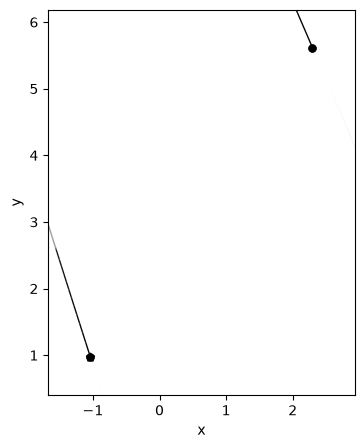

In [19]:
import rebound
def collision_print_only(sim_pointer, collision):
    global collided
    sim = sim_pointer.contents           # get simulation object from pointer
    print(sim.t)                         # print time 
    print(sim.particles[collision.p1].x) # x position of particle 1
    print(sim.particles[collision.p2].x) # x position of particle 2
    collided = True
    return 0                             # Don't remove either particle


collided = False

sim = rebound.Simulation()
#check for collisions
sim.collision = "direct"
sim.collision_resolve = collision_print_only

sim.add(m=1., x=-1, y=-1, z=0, r=0.005)
sim.add(m=1., a=2, r=0.005)
sim.add(m=1., x=5, y=0, z=0, vx=-0.5, r=0.005)
i = 0
steps = 10000
while(not collided and (i < steps)):
    sim.steps(1)
    i += 1
print(i)
rebound.OrbitPlot(sim)

In [3]:
import rebound
import numpy as np
import csv
import itertools
from collections import Counter

#compute basic 2-body orbital elements from relative state vectors
def get_orbital_elements(mu, dx, dy, dz, dvx, dvy, dvz):
    r = np.sqrt(dx**2 + dy**2 + dz**2)
    v2 = dvx**2 + dvy**2 + dvz**2
    rv = dx*dvx + dy*dvy + dz*dvz
    E = 0.5*v2 - mu/r
    
    #bound systems only
    if E < 0:
        a = -mu / (2*E)
    else:
        a = np.inf
        
    hx = dy*dvz - dz*dvy
    hy = dz*dvx - dx*dvz
    hz = dx*dvy - dy*dvx
    h2 = hx**2 + hy**2 + hz**2
    
    #prevent negative sqrt from float precision issues
    e = np.sqrt(max(0, 1 + (2*E*h2)/(mu**2)))
    
    return a, e, E, rv

#run a single 3-body encounter
def simulate_encounter(v_inf, b, phase, r_star=0.005, a_in=0.5, r0=15.0, t_max=500.0, save_traj=False):
    sim = rebound.Simulation()
    sim.G = 1.0
    sim.integrator = "ias15"
    sim.collision = "direct"
    sim.collision_resolve = "halt"
    
    #binary system
    sim.add(m=1., r=r_star)
    sim.add(m=1., a=a_in, e=0., f=phase, r=r_star)
    sim.move_to_com()
    
    #incoming 3rd body
    x3 = np.sqrt(r0**2 - b**2)
    y3 = b
    #energy conservation to find v0
    v0 = np.sqrt(v_inf**2 + 4.0/r0) 
    sim.add(m=1., x=x3, y=y3, z=0., vx=-v0, vy=0., vz=0., r=r_star)
    
    sim.move_to_com()
    
    traj_data = []
    
    #integrate and catch collisions
    try:
        if save_traj:
            #save early trajectory for the first 10 time units
            for t in range(1, 11):
                sim.integrate(t)
                pts = [sim.particles[n] for n in range(3)]
                traj_data.append([p.x for p in pts] + [p.y for p in pts])
        
        sim.integrate(t_max)
    except rebound.Collision:
        return "Collision", traj_data
        
    p = sim.particles
    
    #find the closest pair (inner binary)
    d01 = np.sqrt((p[0].x-p[1].x)**2 + (p[0].y-p[1].y)**2)
    d12 = np.sqrt((p[1].x-p[2].x)**2 + (p[1].y-p[2].y)**2)
    d02 = np.sqrt((p[0].x-p[2].x)**2 + (p[0].y-p[2].y)**2)
    
    dists = {(0,1): d01, (1,2): d12, (0,2): d02}
    i, j = min(dists, key=dists.get)
    k = [x for x in [0,1,2] if x not in (i,j)][0]
    
    #inner binary com
    x_in = (p[i].x*p[i].m + p[j].x*p[j].m) / (p[i].m + p[j].m)
    y_in = (p[i].y*p[i].m + p[j].y*p[j].m) / (p[i].m + p[j].m)
    vx_in = (p[i].vx*p[i].m + p[j].vx*p[j].m) / (p[i].m + p[j].m)
    vy_in = (p[i].vy*p[i].m + p[j].vy*p[j].m) / (p[i].m + p[j].m)
    
    #outer body relative to inner binary
    dx_out, dy_out = p[k].x - x_in, p[k].y - y_in
    dvx_out, dvy_out = p[k].vx - vx_in, p[k].vy - vy_in
    
    #inner binary relative to each other
    dx_in, dy_in = p[i].x - p[j].x, p[i].y - p[j].y
    dvx_in, dvy_in = p[i].vx - p[j].vx, p[i].vy - p[j].vy
    
    #orbital elements
    a_inner, e_inner, E_inner, _ = get_orbital_elements(sim.G*2, dx_in, dy_in, 0, dvx_in, dvy_in, 0)
    a_outer, e_outer, E_outer, rv_outer = get_orbital_elements(sim.G*3, dx_out, dy_out, 0, dvx_out, dvy_out, 0)
    
    #classify based on final energy and Mardling-Aarseth
    if E_outer > 0 and rv_outer > 0:
        return "Ejection", traj_data
        
    if E_outer < 0:
        rp_out = a_outer * (1 - e_outer)
        #mardling & aarseth criterion for equal masses
        threshold = 2.8 * (1.5**0.4) * ((1 + e_outer)**0.4) / ((1 - e_outer)**1.2)
        if (a_outer / a_inner) > threshold:
            return "Stable Hierarchical", traj_data
            
    return "Unresolved", traj_data

#generate full dataset over initial condition grid
def generate_dataset(density_samples=5, output_csv="3body_dataset.csv"):
    v_infs = np.linspace(0.2, 2.0, density_samples)
    bs = np.linspace(0.0, 2.0, density_samples)
    phis = np.linspace(0, 2*np.pi, density_samples, endpoint=False)
    
    combinations = list(itertools.product(v_infs, bs, phis))
    total_runs = len(combinations)
    
    print(f"Starting {total_runs} simulations...")
    
    results_counter = Counter()
    
    with open(output_csv, mode='w', newline='') as file:
        writer = csv.writer(file)
        #header row
        writer.writerow(["v_inf", "b", "phase", "label", "traj_data"])
        
        for idx, (v, b, p) in enumerate(combinations):
            if idx % 50 == 0:
                print(f"Running {idx}/{total_runs}...")
                
            label, traj = simulate_encounter(v, b, p, save_traj=True)
            results_counter[label] += 1
            
            #format early trajectory data as a string for csv storage
            traj_str = str(traj) if traj else ""
            writer.writerow([v, b, p, label, traj_str])
            
    print("Class Proportions:")
    for label, count in results_counter.items():
        print(f"  {label}: {count} ({count/total_runs:.1%})")

#kick off pilot dataset (e.g. 10x10x10 = 1000 samples)
if __name__ == "__main__":
    generate_dataset(density_samples=10, output_csv="pilot_3body_dataset.csv")

Starting 1000 simulations...
Running 0/1000...
Running 50/1000...
Running 100/1000...
Running 150/1000...
Running 200/1000...
Running 250/1000...
Running 300/1000...
Running 350/1000...
Running 400/1000...
Running 450/1000...
Running 500/1000...
Running 550/1000...
Running 600/1000...
Running 650/1000...
Running 700/1000...
Running 750/1000...
Running 800/1000...
Running 850/1000...
Running 900/1000...
Running 950/1000...
Class Proportions:
  Collision: 344 (34.4%)
  Ejection: 639 (63.9%)
  Unresolved: 17 (1.7%)


In [11]:
import rebound
import numpy as np
import csv
import itertools
from collections import Counter

#compute basic 2-body orbital elements from relative state vectors
def get_orbital_elements(mu, dx, dy, dz, dvx, dvy, dvz):
    r = np.sqrt(dx**2 + dy**2 + dz**2)
    v2 = dvx**2 + dvy**2 + dvz**2
    rv = dx*dvx + dy*dvy + dz*dvz
    E = 0.5*v2 - mu/r
    
    #bound systems only
    if E < 0:
        a = -mu / (2*E)
    else:
        a = np.inf
        
    hx = dy*dvz - dz*dvy
    hy = dz*dvx - dx*dvz
    hz = dx*dvy - dy*dvx
    h2 = hx**2 + hy**2 + hz**2
    
    #prevent negative sqrt from float precision issues
    e = np.sqrt(max(0, 1 + (2*E*h2)/(mu**2)))
    
    return a, e, E, rv

#run a single 3-body encounter
def simulate_encounter(a_out, e_out, phase_out, r_star=0.005, a_in=0.5, t_max=1500.0, save_traj=False):
    sim = rebound.Simulation()
    sim.G = 1.0
    sim.integrator = "ias15"
    sim.collision = "direct"
    sim.collision_resolve = "halt"
    
    #inner binary system
    sim.add(m=1., r=r_star)
    sim.add(m=1., a=a_in, e=0., f=0., r=r_star)
    sim.move_to_com()
    
    #bound outer 3rd body (orbits inner binary center of mass)
    sim.add(m=1., a=a_out, e=e_out, f=phase_out, r=r_star)
    
    traj_data = []
    
    #integrate and catch collisions
    try:
        if save_traj:
            #save early trajectory for the first 10 time units
            for t in range(1, 11):
                sim.integrate(t)
                pts = [sim.particles[n] for n in range(3)]
                traj_data.append([p.x for p in pts] + [p.y for p in pts])
        
        sim.integrate(t_max)
    except rebound.Collision:
        return "Collision", traj_data
        
    p = sim.particles
    
    #find the closest pair (inner binary)
    d01 = np.sqrt((p[0].x-p[1].x)**2 + (p[0].y-p[1].y)**2)
    d12 = np.sqrt((p[1].x-p[2].x)**2 + (p[1].y-p[2].y)**2)
    d02 = np.sqrt((p[0].x-p[2].x)**2 + (p[0].y-p[2].y)**2)
    
    dists = {(0,1): d01, (1,2): d12, (0,2): d02}
    i, j = min(dists, key=dists.get)
    k = [x for x in [0,1,2] if x not in (i,j)][0]
    
    #inner binary com
    x_in = (p[i].x*p[i].m + p[j].x*p[j].m) / (p[i].m + p[j].m)
    y_in = (p[i].y*p[i].m + p[j].y*p[j].m) / (p[i].m + p[j].m)
    vx_in = (p[i].vx*p[i].m + p[j].vx*p[j].m) / (p[i].m + p[j].m)
    vy_in = (p[i].vy*p[i].m + p[j].vy*p[j].m) / (p[i].m + p[j].m)
    
    #outer body relative to inner binary
    dx_out, dy_out = p[k].x - x_in, p[k].y - y_in
    dvx_out, dvy_out = p[k].vx - vx_in, p[k].vy - vy_in
    
    #inner binary relative to each other
    dx_in, dy_in = p[i].x - p[j].x, p[i].y - p[j].y
    dvx_in, dvy_in = p[i].vx - p[j].vx, p[i].vy - p[j].vy
    
    #orbital elements
    a_inner, e_inner, E_inner, _ = get_orbital_elements(sim.G*2, dx_in, dy_in, 0, dvx_in, dvy_in, 0)
    a_outer, e_outer, E_outer, rv_outer = get_orbital_elements(sim.G*3, dx_out, dy_out, 0, dvx_out, dvy_out, 0)
    
    #classify based on final energy and Mardling-Aarseth
    if E_outer > 0 and rv_outer > 0:
        return "Ejection", traj_data
        
    if E_outer < 0:
        rp_out = a_outer * (1 - e_outer)
        #mardling & aarseth criterion for equal masses
        threshold = 2.8 * (1.5**0.4) * ((1 + e_outer)**0.4) / ((1 - e_outer)**1.2)
        if (a_outer / a_inner) > threshold:
            return "Stable Hierarchical", traj_data
            
    return "Unresolved", traj_data

#generate full dataset over initial condition grid
def generate_dataset(density_samples=5, output_csv="bound_triple_dataset.csv"):
    a_outs = np.linspace(1.2, 4.0, density_samples)
    e_outs = np.linspace(0.0, 0.8, density_samples)
    phis = np.linspace(0, 2*np.pi, density_samples, endpoint=False)
    
    combinations = list(itertools.product(a_outs, e_outs, phis))
    total_runs = len(combinations)
    
    print(f"Starting {total_runs} simulations...")
    
    results_counter = Counter()
    
    with open(output_csv, mode='w', newline='') as file:
        writer = csv.writer(file)
        #header row
        writer.writerow(["a_out", "e_out", "phase_out", "label", "traj_data"])
        
        for idx, (a_out, e_out, p) in enumerate(combinations):
            if idx % 50 == 0:
                print(f"Running {idx}/{total_runs}...")
                
            label, traj = simulate_encounter(a_out, e_out, p, save_traj=True)
            results_counter[label] += 1
            
            #format early trajectory data as a string for csv storage
            traj_str = str(traj) if traj else ""
            writer.writerow([a_out, e_out, p, label, traj_str])
            
    print("Class Proportions:")
    for label, count in results_counter.items():
        print(f"  {label}: {count} ({count/total_runs:.1%})")

#kick off pilot dataset (e.g. 10x10x10 = 1000 samples)
if __name__ == "__main__":
    generate_dataset(density_samples=10, output_csv="pilot_3body_dataset.csv")

Starting 1000 simulations...
Running 0/1000...
Running 50/1000...
Running 100/1000...
Running 150/1000...
Running 200/1000...
Running 250/1000...
Running 300/1000...
Running 350/1000...
Running 400/1000...
Running 450/1000...
Running 500/1000...
Running 550/1000...
Running 600/1000...
Running 650/1000...
Running 700/1000...
Running 750/1000...
Running 800/1000...
Running 850/1000...
Running 900/1000...
Running 950/1000...
Class Proportions:
  Unresolved: 288 (28.8%)
  Ejection: 331 (33.1%)
  Collision: 79 (7.9%)
  Stable Hierarchical: 302 (30.2%)


In [ ]:
#need to try and get less unresolved, make eccentricity of outer orbit higher next